<a href="https://colab.research.google.com/github/jihadi2623-dot/computer-vision-/blob/main/Welcome_to_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

23-54298-3

In [6]:
#Import Required Libraries
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np

device = 'cuda' if torch.cuda.is_available() else 'cpu'

print(device)

cuda


zip_path = "/content/plant_dataset.zip"

with open(zip_path, "wb") as file:
    file.write(response.content)

print("Dataset Saved Successfully!")

In [7]:
#Download Dataset from Mendeley Data
import requests

url = "https://data.mendeley.com/public-api/zip/5g238dv4ht/download/1"

response = requests.get(url)

print("Status Code:", response.status_code)
print("File Size:", len(response.content))

Status Code: 200
File Size: 3420562991


In [4]:
#Save Downloaded Dataset as ZIP File
zip_path = "/content/plant_dataset.zip"

with open(zip_path, "wb") as file:
    file.write(response.content)

print("Dataset Saved Successfully!")

Dataset Saved Successfully!


In [5]:
#Extract ZIP Dataset
import zipfile

extract_path = "/content/plant_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset Extracted Successfully!")

Dataset Extracted Successfully!


In [6]:
#Explore Extracted Dataset Folders

import os

print(os.listdir(extract_path))

['Plant Leaf Disease Recognition Dataset']


In [7]:
#Display Dataset Files and Folders

import os

files = os.listdir(extract_path)

print("Dataset Files and Folders:")

for file in files:
    print(file)

Dataset Files and Folders:
Plant Leaf Disease Recognition Dataset


In [9]:
#Explore Main Dataset Folder

import os

folder_path = os.path.join(extract_path, "Plant Leaf Disease Recognition Dataset")

print(os.listdir(folder_path))

['Data for Leaf Disease.zip']


In [10]:
#Extract Data for Leaf Disease ZIP File
import zipfile
import os

zip_path = os.path.join(folder_path, "Data for Leaf Disease.zip")
new_extract_path = "/content/leaf_data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(new_extract_path)

print("Dataset Extracted Successfully!")
print(os.listdir(new_extract_path))

Dataset Extracted Successfully!
['Data for Leaf Disease']


In [11]:
#Count Total Images in Dataset
import os

total_images = 0

for folder, subfolders, files in os.walk(new_extract_path):
    for file in files:
        if file.endswith(('.jpg', '.jpeg', '.png')):
            total_images += 1

print("Total Images:", total_images)

Total Images: 25077


In [12]:
#Explore Main Dataset Subfolders
import os

for folder in os.listdir(new_extract_path):
    folder_path = os.path.join(new_extract_path, folder)

    if os.path.isdir(folder_path):
        print(folder)

Data for Leaf Disease


In [13]:
#Explore Data for Leaf Disease Folder
import os

path = os.path.join(new_extract_path, "Data for Leaf Disease")

print(os.listdir(path))

['Image Augmentation', 'Background Removed']


In [14]:
#Explore Background Removed Dataset
import os

path = "/content/leaf_data/Data for Leaf Disease/Background Removed"

print(os.listdir(path))

['hibiscus', 'Gourd', 'zucchini', 'Papaya']


In [15]:
#Count Images in Each Class Folder
import os

path = "/content/leaf_data/Data for Leaf Disease/Background Removed"

for folder in os.listdir(path):
    folder_path = os.path.join(path, folder)

    images = os.listdir(folder_path)

    print(folder, "=", len(images))

hibiscus = 1328
Gourd = 1147
zucchini = 1099
Papaya = 547


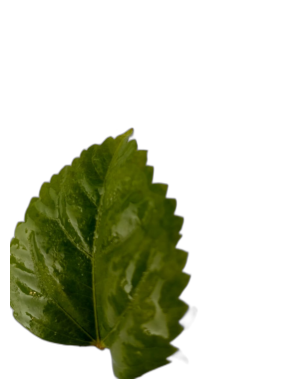

In [16]:
#Visualize Sample Image from Dataset

import matplotlib.pyplot as plt
import os

path = "/content/leaf_data/Data for Leaf Disease/Background Removed/hibiscus"

image_name = os.listdir(path)[0]

image_path = os.path.join(path, image_name)

img = plt.imread(image_path)

plt.imshow(img)
plt.axis('off')
plt.show()

In [17]:
#Import Required Libraries and Set Device
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
import os

device = 'cuda' if torch.cuda.is_available() else 'cpu'

print("Device:", device)

Device: cuda


In [2]:
from torchvision import transforms

In [4]:
#Define Image Transformation and Preprocessing
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

In [19]:
#Load Image Dataset Using ImageFolder
dataset_path = "/content/leaf_data/Data for Leaf Disease/Background Removed"

dataset = datasets.ImageFolder(
    root=dataset_path,
    transform=transform
)

print("Total Images:", len(dataset))
print("Classes:", dataset.classes)

Total Images: 4121
Classes: ['Gourd', 'Papaya', 'hibiscus', 'zucchini']


In [20]:
#Create DataLoader for Batch Processing
train_loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)

print("DataLoader Created Successfully!")

DataLoader Created Successfully!


In [21]:
#Check Image Batch Shape and Labels
images, labels = next(iter(train_loader))

print("Image Shape:", images.shape)
print("Labels:", labels)

Image Shape: torch.Size([32, 3, 128, 128])
Labels: tensor([0, 1, 2, 2, 2, 2, 0, 0, 1, 2, 3, 3, 2, 2, 0, 0, 0, 2, 2, 2, 2, 0, 2, 0,
        2, 2, 2, 2, 2, 0, 0, 2])


In [22]:
print(dataset.class_to_idx)

{'Gourd': 0, 'Papaya': 1, 'hibiscus': 2, 'zucchini': 3}


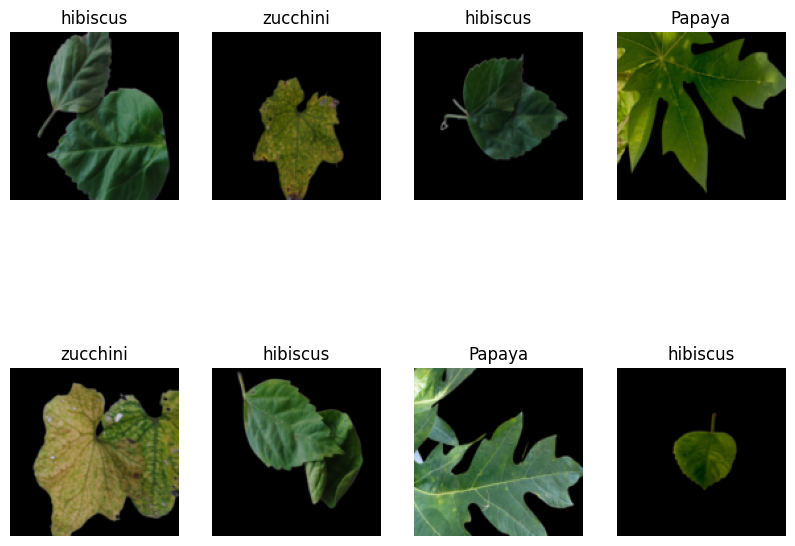

In [23]:
#Visualize Sample Images with Class Labels
images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 8))

for i in range(8):
    plt.subplot(2, 4, i+1)

    img = images[i].permute(1, 2, 0)

    plt.imshow(img)
    plt.title(dataset.classes[labels[i]])
    plt.axis('off')

plt.show()

In [31]:
#Split Dataset into Training, Validation and Testing Sets
from torch.utils.data import random_split

train_size = int(0.70 * len(dataset))
val_size = int(0.15 * len(dataset))
test_size = len(dataset) - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size]
)

print("Training Images:", len(train_dataset))
print("Validation Images:", len(val_dataset))
print("Testing Images:", len(test_dataset))

Training Images: 2884
Validation Images: 618
Testing Images: 619


In [32]:
#Create DataLoaders for Training, Validation and Testing
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("All DataLoaders Created Successfully!")

All DataLoaders Created Successfully!


In [33]:
#Check Training, Validation and Testing Data Shapes

train_images, train_labels = next(iter(train_loader))
val_images, val_labels = next(iter(val_loader))
test_images, test_labels = next(iter(test_loader))

print("Train Shape:", train_images.shape)
print("Validation Shape:", val_images.shape)
print("Test Shape:", test_images.shape)

Train Shape: torch.Size([32, 3, 128, 128])
Validation Shape: torch.Size([32, 3, 128, 128])
Test Shape: torch.Size([32, 3, 128, 128])


In [36]:
#Build Convolutional Neural Network (CNN) Model Architecture
import torch
import torch.nn as nn

class CNN(nn.Module):

    def __init__(self):
        super(CNN, self).__init__()

        self.conv = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        self.fc = nn.Sequential(

            nn.Flatten(),

            nn.Linear(128 * 16 * 16, 256),

            nn.ReLU(),

            nn.Dropout(0.5),

            nn.Linear(256, 4)
        )

    def forward(self, x):

        x = self.conv(x)

        x = self.fc(x)

        return x


device = 'cuda' if torch.cuda.is_available() else 'cpu'

model = CNN().to(device)

print(model)

CNN(
  (conv): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32768, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=4, bias=True)
  )
)


In [37]:
#Define Loss Function and Optimizer
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss Function:", criterion)
print("Optimizer:", optimizer)

Loss Function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [38]:
#Train CNN Model
epochs = 10

train_losses = []
train_accuracies = []

for epoch in range(epochs):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    accuracy = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(accuracy)

    print(f"Epoch [{epoch+1}/{epochs}] "
          f"Loss: {epoch_loss:.4f} "
          f"Accuracy: {accuracy:.2f}%")

Epoch [1/10] Loss: 0.8214 Accuracy: 65.81%
Epoch [2/10] Loss: 0.4440 Accuracy: 83.15%
Epoch [3/10] Loss: 0.3308 Accuracy: 87.59%
Epoch [4/10] Loss: 0.1968 Accuracy: 92.61%
Epoch [5/10] Loss: 0.1592 Accuracy: 94.17%
Epoch [6/10] Loss: 0.1198 Accuracy: 95.70%
Epoch [7/10] Loss: 0.0761 Accuracy: 97.33%
Epoch [8/10] Loss: 0.0850 Accuracy: 96.98%
Epoch [9/10] Loss: 0.0580 Accuracy: 97.92%
Epoch [10/10] Loss: 0.0546 Accuracy: 98.13%


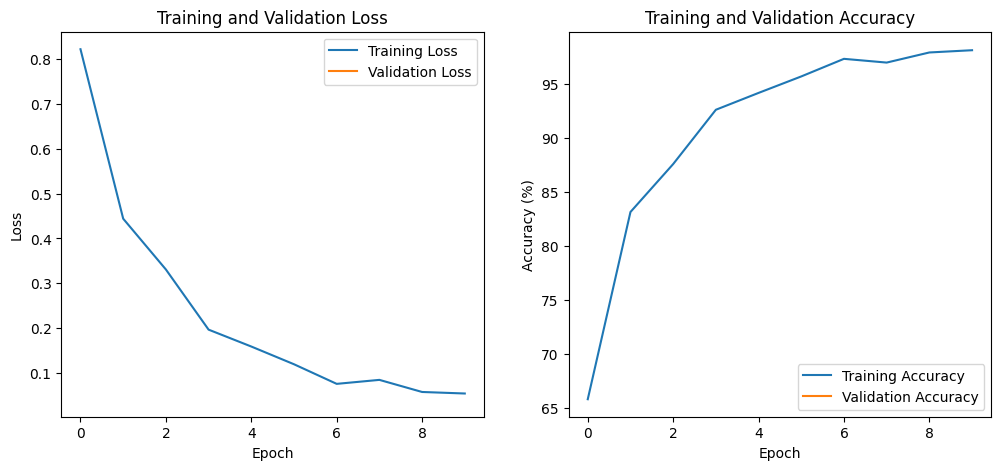

In [39]:
#Visualize Training and Validation Performance
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Loss Graph
plt.subplot(1, 2, 1)

plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')

plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Accuracy Graph
plt.subplot(1, 2, 2)

plt.plot(train_accuracies, label='Training Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')

plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()

plt.show()

In [40]:
#Evaluate CNN Model Using Test Accuracy
from sklearn.metrics import accuracy_score

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

accuracy = accuracy_score(all_labels, all_predictions)

print("Test Accuracy:", accuracy * 100, "%")

Test Accuracy: 95.31502423263328 %


In [41]:
#Generate Classification Report
from sklearn.metrics import classification_report

print(classification_report(
    all_labels,
    all_predictions,
    target_names=dataset.classes
))

              precision    recall  f1-score   support

       Gourd       0.93      0.91      0.92       151
      Papaya       0.97      0.96      0.97        78
    hibiscus       0.96      0.97      0.96       222
    zucchini       0.96      0.96      0.96       168

    accuracy                           0.95       619
   macro avg       0.96      0.95      0.95       619
weighted avg       0.95      0.95      0.95       619



Saving 1-papaya-leaves-unbranded-whole-no-original-imahek6cf3dvenfe.webp to 1-papaya-leaves-unbranded-whole-no-original-imahek6cf3dvenfe (1).webp


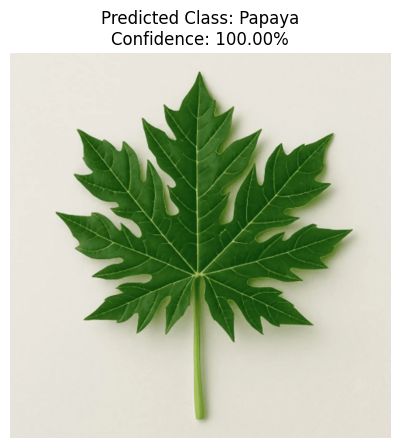

In [44]:
#Predict New Leaf Image and Display Prediction Result
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
import torch

# Upload Image
uploaded = files.upload()

# Read Image
image_path = list(uploaded.keys())[0]
img = Image.open(image_path).convert('RGB')

# Preprocessing
input_image = transform(img)
input_image = input_image.unsqueeze(0).to(device)

# Prediction
model.eval()

with torch.no_grad():
    output = model(input_image)
    probabilities = torch.softmax(output, dim=1)
    confidence, predicted = torch.max(probabilities, 1)

# Get Class Name
predicted_class = dataset.classes[predicted.item()]

# Show Image with Prediction
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title(
    f"Predicted Class: {predicted_class}\n"
    f"Confidence: {confidence.item()*100:.2f}%"
)
plt.axis('off')
plt.show()